<a href="https://colab.research.google.com/github/gbenihonkenoukon-dotcom/AI-for-Science-and-Engineering-online-course/blob/main/Week_6_Assignment_Gbenihon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Week 6 Assignment | Discovering Patterns in Data**

**Features to investigate:**
- Stress
- Void ratio

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from google.colab import files

uploaded = files.upload()

file_name = "Dataset for training_Organized.xlsx"
df = pd.read_excel(file_name)

print("Column names:")
print(df.columns.tolist())

display(df.head())

Saving Dataset for training_Organized.xlsx to Dataset for training_Organized (1).xlsx
Column names:
['stress', 'strain', 'void ratio']


,stress,strain,void ratio
0,12.6,0.0144,2.581670
1,15.3,0.0168,2.572949
2,18.8,0.0192,2.564227
3,22.4,0.0215,2.555869
4,26.1,0.0239,2.547147


In [6]:
data = df[["stress", "void ratio"]]

# Standardizing of the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)

# Testing different numbers of clusters
max_k = min(10, len(data) - 1)

k_values = range(2, max_k + 1)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Display the evaluation results
evaluation = pd.DataFrame({
    "Number of clusters": list(k_values),
    "Inertia": inertias,
    "Silhouette score": silhouette_scores
})

display(evaluation)


,Number of clusters,Inertia,Silhouette score
0,2,781.304347,0.574596
1,3,376.695516,0.533744
2,4,227.796876,0.510494
3,5,156.849378,0.489280
4,6,117.544505,0.471022
5,7,92.743184,0.457781
6,8,76.019091,0.446146
7,9,64.465943,0.434052
8,10,56.350181,0.420801


**Plotting elbow method and silhouette scores**

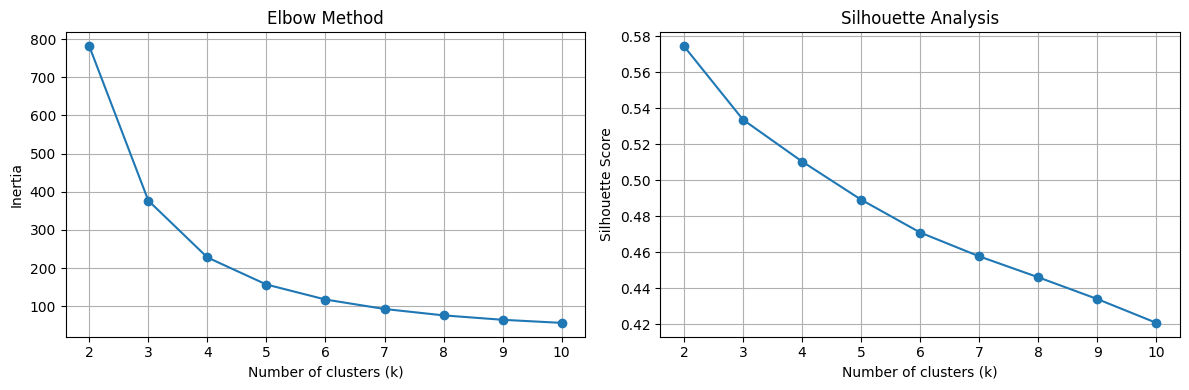

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Elbow method
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")
axes[0].grid(True)

# Silhouette score
axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Analysis")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [9]:
#Selecting the number of clusters (K-means) and prediction with optimal K-means

# Select k with the highest silhouette score
best_index = int(np.argmax(silhouette_scores))
selected_k = list(k_values)[best_index]

print("Selected number of clusters:", selected_k)

# Fit the final K-means model
kmeans = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)

data = data.copy() # to add a new column called "Cluster"
data["Cluster"] = kmeans.fit_predict(X_scaled) + 1

display(data.head())

Selected number of clusters: 2


,stress,void ratio,Cluster
0,12.6,2.581670,1
1,15.3,2.572949,1
2,18.8,2.564227,1
3,22.4,2.555869,1
4,26.1,2.547147,1


**Visualizing the clusters**

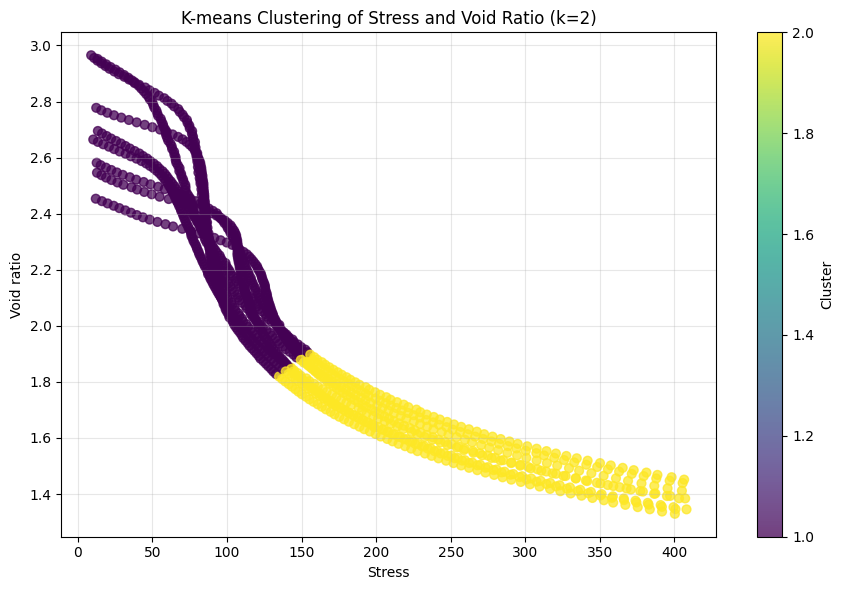

In [12]:

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    data["stress"],
    data["void ratio"],
    c=data["Cluster"],
    cmap="viridis",
    s=40,
    alpha=0.75
)

plt.xlabel("Stress")
plt.ylabel("Void ratio")
plt.title(f"K-means Clustering of Stress and Void Ratio (k={selected_k})")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Describing the characteristics of each cluster**

In [13]:
#Calculating the number of observations, mean, median, and range of stress and void ratio in each group

cluster_summary = data.groupby("Cluster").agg(
    Number_of_observations=("stress", "size"),
    Mean_stress=("stress", "mean"),
    Median_stress=("stress", "median"),
    Mean_void_ratio=("void ratio", "mean"),
    Median_void_ratio=("void ratio", "median"),
    Minimum_stress=("stress", "min"),
    Maximum_stress=("stress", "max"),
    Minimum_void_ratio=("void ratio", "min"),
    Maximum_void_ratio=("void ratio", "max")
).round(4)

display(cluster_summary)


,Number_of_observations,Mean_stress,Median_stress,Mean_void_ratio,Median_void_ratio,Minimum_stress,Maximum_stress,Minimum_void_ratio,Maximum_void_ratio
Cluster,,,,,,,,,
1,735,89.7679,90.50,2.3028,2.2872,8.9,153.9,1.8281,2.9651
2,448,244.2112,228.65,1.6199,1.6212,134.9,408.1,1.3296,1.8978


**Discussion on what each cluster might represent**

K-means clustering was applied to the stress and void ratio
features. Both features were standardized before clustering. The selected number of clusters was 2, based on the silhouette score equal to 0.5746.

Looking at the elbow plot, silhouette score, scatter plot and cluster descriptive table together, the identified groups represent two different physical states.

Cluster 1 is characterized by lower stress and higher void ratios. This group represent soil behavior at relatively low stress levels, where the soil structure retains a higher void ratio. These observations could correspond to the less-compressed portion of the stress–void ratio curve.

Cluster 2 is characterized by higher stress and lower void ratios.
This group may represent physical behaviour of soil under higher stress levels, where compression has reduced the void ratio.

These interpretations are consistent with the general geotechnical relationship between effective stress and void ratio during soil compression.